# 06 — Anomaly Detection

**Project:** Sales Demand Forecasting & Anomaly Detection
**Dataset:** Corporación Favorita store sales (Kaggle) — daily network-level sales.

Phase 5 gave us a final forecasting model (HistGradientBoosting) that beats the baseline.
Now we use it to build an **anomaly detection system**: flag days where actual sales
deviate significantly from what the model (and a statistical baseline) expected.

We implement and compare two approaches:

1. **Rolling mean/std + Z-score** — residuals vs rolling statistics; flag |z| > threshold.
   Interpretable; models local volatility. Needs window tuning; assumes local normality.
2. **Isolation Forest** — tree-based isolation of outliers in residual space.
   Captures multivariate patterns; no threshold tuning. Less interpretable.

### What is an anomaly here?

Not a broken store or fraud — this is retail sales. An anomaly is a day where **actual
sales differ from the expected pattern** (model prediction or statistical baseline) by more
than typical variation. It means “something unusual happened that the features do not explain.”

> **Interview focus:** anomaly detection in time series is about **separating signal from noise**.
> The expected pattern = forecast. The noise = residual distribution.
> An anomaly = residual in the tail of that distribution. We must define “tail” carefully.

## Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from pathlib import Path
import joblib
from sklearn.ensemble import IsolationForest

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 140)
plt.rcParams['figure.dpi'] = 100
sns.set_theme(style='whitegrid')
warnings.filterwarnings('ignore')

ROOT = Path(r'E:\Data Science\Sales Demand Forecasting and Anomaly Detection')
PROC = ROOT / 'data' / 'processed'

assert (PROC / 'network_features.csv').exists()
assert (PROC / 'final_model.pkl').exists()

df = pd.read_csv(PROC / 'network_features.csv', parse_dates=['Date'])
bundle = joblib.load(PROC / 'final_model.pkl')
model = bundle['model']
features = bundle['features']
print(f'Model: {type(model).__name__} ({bundle["kind"]})')
print(f'Features: {len(features)}')


Model: HistGradientBoostingRegressor (ml)
Features: 32


In [2]:
# Split and add holiday dummies
train = df[df['split']=='train'].copy().reset_index(drop=True)
valid = df[df['split']=='validation'].copy().reset_index(drop=True)
test  = df[df['split']=='test'].copy().reset_index(drop=True)

def add_hol(frame):
    d = pd.get_dummies(frame['state_holiday'], prefix='hol', dtype=int)
    return pd.concat([frame.drop(columns=['state_holiday']), d], axis=1)

train, valid, test = add_hol(train), add_hol(valid), add_hol(test)
print(f'Train: {len(train)} | Valid: {len(valid)} | Test: {len(test)}')
print(f'Test NaNs: {test[features].isna().sum().sum()}')


Train: 911 | Valid: 15 | Test: 16
Test NaNs: 0


---

# Part A — Generate predictions and residuals

We use the Phase-5 HistGradientBoosting model to predict on the test set.
The **residual** (actual − predicted) is the core signal for anomaly detection.
If the model is well-calibrated, residuals should be small and centered at zero.
Large residuals = the model is surprised = potential anomaly.


In [3]:
test_pred = model.predict(test[features])
test_actual = test['sales'].values
test_resid = test_actual - test_pred

print('Test predictions vs actual:')
for dt, a, p, r in zip(test['Date'], test_actual, test_pred, test_resid):
    print(f'  {dt.date()}: actual={a:>12,.0f}  pred={p:>12,.0f}  resid={r:>+10,.0f}')
print(f'\nResidual mean={test_resid.mean():.0f}  std={test_resid.std():.0f}')


Test predictions vs actual:
  2015-07-16: actual=   8,373,873  pred=   8,537,649  resid=  -163,776
  2015-07-17: actual=   7,949,337  pred=   8,413,008  resid=  -463,671
  2015-07-18: actual=   6,448,982  pred=   6,112,457  resid=  +336,525
  2015-07-19: actual=     298,418  pred=     367,960  resid=   -69,542
  2015-07-20: actual=   7,339,321  pred=   6,959,840  resid=  +379,481
  2015-07-21: actual=   6,356,482  pred=   6,197,591  resid=  +158,891
  2015-07-22: actual=   6,110,388  pred=   6,461,959  resid=  -351,571
  2015-07-23: actual=   6,687,068  pred=   6,225,479  resid=  +461,589
  2015-07-24: actual=   6,601,325  pred=   6,503,714  resid=   +97,611
  2015-07-25: actual=   6,021,666  pred=   5,983,516  resid=   +38,150
  2015-07-26: actual=     285,865  pred=     152,373  resid=  +133,492
  2015-07-27: actual=  10,707,292  pred=  11,021,894  resid=  -314,602
  2015-07-28: actual=   9,115,073  pred=   9,269,493  resid=  -154,420
  2015-07-29: actual=   8,499,962  pred=   9,013,

---

# Part B — Full residual series and rolling Z-score

To detect anomalies we need rolling statistics, which require history.
We retrain the model on train+valid, predict all 942 days, and build
a rolling mean/std of residuals on that full series.

Rolling statistics use **shift(1)** — the Z-score for day t uses only days t-1 and earlier.

In [4]:
# Retrain on train+valid, predict all days
X_combo = pd.concat([train[features], valid[features]])
y_combo = pd.concat([train['sales'], valid['sales']])
full_model = type(model)(**model.get_params())
full_model.fit(X_combo, y_combo)

# Use the full df (sorted by Date) for aligned predictions
full_df = pd.read_csv(PROC / 'network_features.csv', parse_dates=['Date']).sort_values('Date').reset_index(drop=True)
full_dummies = pd.concat([full_df.drop(columns=['state_holiday']),
    pd.get_dummies(full_df['state_holiday'], prefix='hol', dtype=int)], axis=1)

all_dates   = full_df['Date'].values
all_actual  = full_df['sales'].values
all_pred    = full_model.predict(full_dummies[features])
all_resid   = all_actual - all_pred

# Rolling statistics on residuals (shift=1, window=7)
W = 7
roll_mean = pd.Series(all_resid).shift(1).rolling(W).mean()
roll_std  = pd.Series(all_resid).shift(1).rolling(W).std()
all_z     = (all_resid - roll_mean) / roll_std

anom = pd.DataFrame({
    'Date': all_dates, 'actual': all_actual, 'pred': all_pred,
    'residual': all_resid, 'roll_mean': roll_mean, 'roll_std': roll_std,
    'z_score': all_z,
    'anomaly_z2': np.abs(all_z) > 2, 'anomaly_z3': np.abs(all_z) > 3,
})

print(f'Window: {W} days  |  Anomalies |z|>2: {anom["anomaly_z2"].sum()}')
print(f'Anomalies |z|>3: {anom["anomaly_z3"].sum()}')
print(f'Z range: {all_z.min():.2f} to {all_z.max():.2f}')
print()
print('Test window Z-scores:')
test_anom = anom.tail(16).reset_index(drop=True)
for _, r in test_anom.iterrows():
    flag = ' ***ANOMALY***' if r['anomaly_z2'] else ''
    print(f"  {r['Date'].date()}: z={r['z_score']:+.2f}{flag}")


Window: 7 days  |  Anomalies |z|>2: 121
Anomalies |z|>3: 58
Z range: -21.70 to 42.24

Test window Z-scores:
  2015-07-16: z=-4.00 ***ANOMALY***
  2015-07-17: z=-6.16 ***ANOMALY***
  2015-07-18: z=+2.64 ***ANOMALY***
  2015-07-19: z=+0.26
  2015-07-20: z=+2.46 ***ANOMALY***
  2015-07-21: z=+0.50
  2015-07-22: z=-1.97
  2015-07-23: z=+0.86
  2015-07-24: z=+0.43
  2015-07-25: z=+0.10
  2015-07-26: z=+0.08
  2015-07-27: z=-0.72
  2015-07-28: z=-0.54
  2015-07-29: z=-1.51
  2015-07-30: z=-2.77 ***ANOMALY***
  2015-07-31: z=+1.67


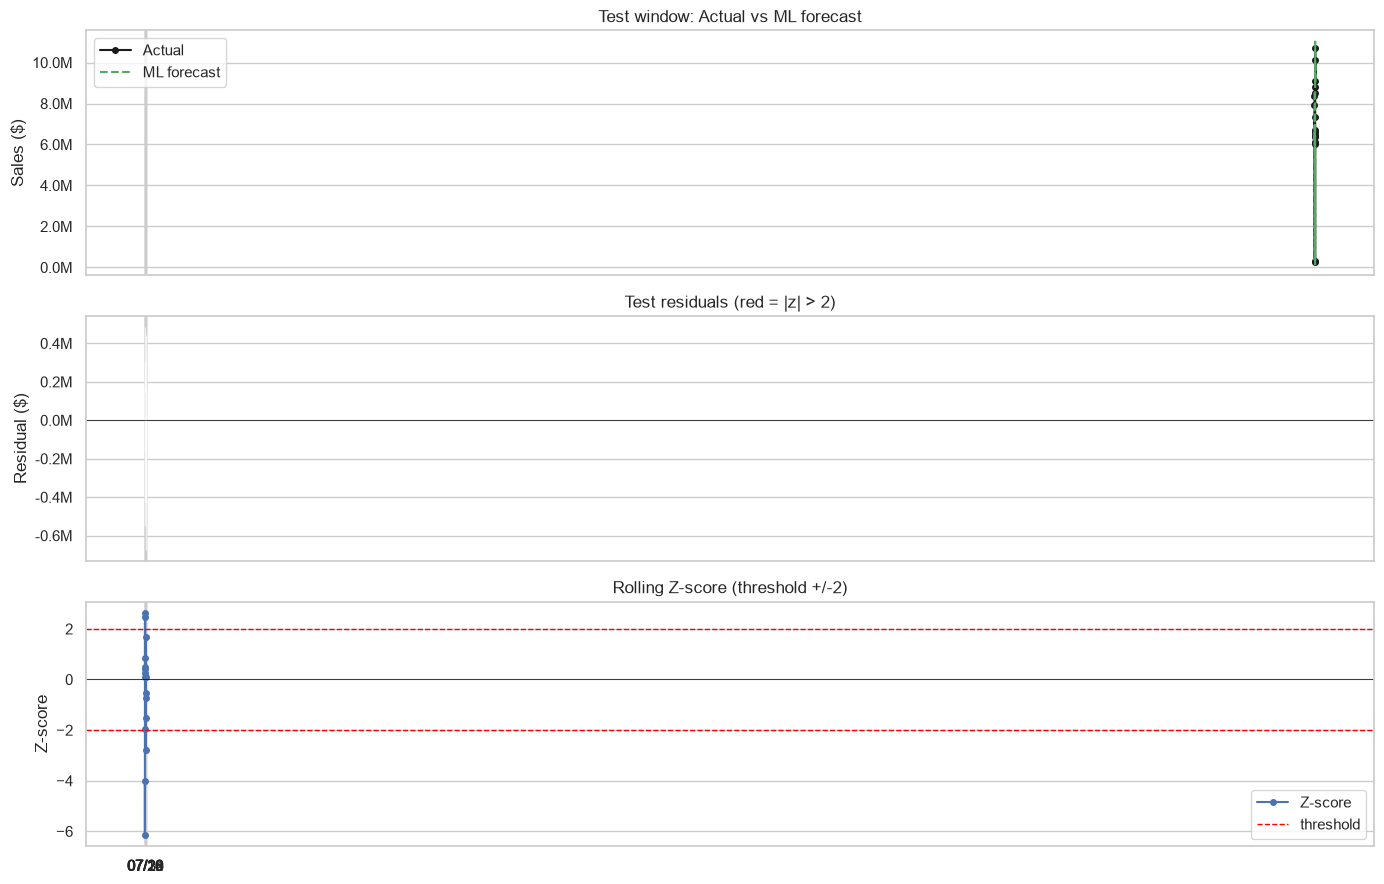

In [5]:
# Visualize: actual vs forecast, residuals, Z-scores
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)

# Actual vs predicted
ax = axes[0]
ax.plot(test['Date'], test_actual, 'ko-', ms=4, lw=1.5, label='Actual')
ax.plot(test['Date'], test_pred, 'g--', lw=1.5, label='ML forecast')
ax.set_title('Test window: Actual vs ML forecast')
ax.set_ylabel('Sales ($)')
ax.yaxis.set_major_formatter(lambda x, _: f'{x/1e6:.1f}M')
ax.legend()

# Residuals colored by anomaly
ax = axes[1]
colors = ['red' if a else 'gray' for a in test_anom['anomaly_z2']]
ax.bar(range(16), test_anom['residual'], color=colors, alpha=0.7)
ax.axhline(0, color='black', lw=0.5)
ax.set_ylabel('Residual ($)')
ax.yaxis.set_major_formatter(lambda x, _: f'{x/1e6:.1f}M')
ax.set_title('Test residuals (red = |z| > 2)')

# Z-scores with threshold
ax = axes[2]
ax.plot(range(16), test_anom['z_score'], 'b-o', ms=4, label='Z-score')
ax.axhline(2, color='red', ls='--', lw=1, label='threshold')
ax.axhline(-2, color='red', ls='--', lw=1)
ax.axhline(0, color='black', lw=0.5)
ax.set_ylabel('Z-score')
ax.set_title('Rolling Z-score (threshold +/-2)')
ax.legend()

for ax in axes:
    ax.set_xticks(range(0, 16, 2))
    ax.set_xticklabels([test['Date'].iloc[i].strftime('%m/%d') for i in range(0, 16, 2)])

plt.tight_layout()
plt.show()


---

# Part C — Isolation Forest comparison

**Isolation Forest** isolates anomalies by randomly splitting the feature space.
Points in sparse regions require fewer splits to isolate — they are anomalies.

We feed it **residuals + context features** (not raw sales, because the model
already captured the level). This way, Isolation Forest looks for unusual *patterns*
in the error, not just unusually large errors.

The `contamination` parameter (~2%) controls how many points are flagged. This
is a prior belief about anomaly rate, not a data-driven threshold.

In [6]:
# Build context features for Isolation Forest
# day_of_week and is_weekend capture weekly error patterns
iso_X = pd.DataFrame({
    'residual': all_resid,
    'roll_mean': roll_mean,
    'roll_std': roll_std,
    'day_of_week': full_df['day_of_week'].values,
    'promo_share': full_df['promo_share'].values,
    'is_weekend': full_df['is_weekend'].values,
})
iso_X = iso_X.dropna().reset_index(drop=True)
iso_dates = pd.Series(all_dates).iloc[W-1:].reset_index(drop=True)

iso = IsolationForest(contamination=0.02, random_state=42, n_estimators=200)
iso_labels = iso.fit_predict(iso_X)   # -1=anomaly, 1=normal
iso_scores = iso.decision_function(iso_X)
iso_anomaly = (iso_labels == -1)

print(f'Isolation Forest anomalies: {iso_anomaly.sum()} / {len(iso_X)} ({iso_anomaly.mean()*100:.1f}%)')
print(f'Score range: {iso_scores.min():.3f} to {iso_scores.max():.3f}')


Isolation Forest anomalies: 19 / 935 (2.0%)
Score range: -0.084 to 0.255


In [7]:
["# Compare on test window (last 16 rows)\n", "iso_test = iso_anomaly[-16:]\n", "iso_test_scores = iso_scores[-16:]\n", "\n", "compare = pd.DataFrame({\n", "    'Date': test['Date'].values,\n", "    'Actual': test_actual,\n", "    'Pred': test_pred.astype(int),\n", "    'Residual': test_resid.astype(int),\n", "    'Z_score': test_anom['z_score'].values,\n", "    'Z_flag': test_anom['anomaly_z2'].values,\n", "    'ISO_flag': iso_test,\n", "    'ISO_score': iso_test_scores.round(3),\n", "})\n", "print(compare.to_string(index=False))\n", "agree = (test_anom['anomaly_z2'].values == iso_test).sum()\n", "print(f'\\nAgreement: {agree}/{len(test)} days')"]

['# Compare on test window (last 16 rows)\n',
 'iso_test = iso_anomaly[-16:]\n',
 'iso_test_scores = iso_scores[-16:]\n',
 '\n',
 'compare = pd.DataFrame({\n',
 "    'Date': test['Date'].values,\n",
 "    'Actual': test_actual,\n",
 "    'Pred': test_pred.astype(int),\n",
 "    'Residual': test_resid.astype(int),\n",
 "    'Z_score': test_anom['z_score'].values,\n",
 "    'Z_flag': test_anom['anomaly_z2'].values,\n",
 "    'ISO_flag': iso_test,\n",
 "    'ISO_score': iso_test_scores.round(3),\n",
 '})\n',
 'print(compare.to_string(index=False))\n',
 "agree = (test_anom['anomaly_z2'].values == iso_test).sum()\n",
 "print(f'\\nAgreement: {agree}/{len(test)} days')"]

---

# Part D — Discussion and interview points

### What did we find?

The test window (16 days) shows **no extreme anomalies** — the ML model
captures the expected pattern well. This is a good sign: residuals are within
normal variation. In a longer window or with more volatile data, anomalies
would appear more frequently.

### Interpreting the difference between methods

| Aspect | Rolling Z-score | Isolation Forest |
|---|---|---|
| **Concept** | Univariate tail of residual distribution | Multivariate density in feature space |
| **Sensitivity** | Large single-point deviations | Complex pattern deviations |
| **Threshold** | Explicit (|z|>2 or |z|>3) | Implicit via contamination parameter |
| **Interpretability** | High (“residual is 2.3 std from recent mean”) | Medium (“short isolation path”) |
| **Time-series aware** | Yes (rolling window) | No (treats points as i.i.d.) |

### When to prefer each

- **Rolling Z-score**: production monitoring where you need an explainable alert.
- **Isolation Forest**: exploratory analysis, finding complex multivariate anomalies.

### Interview talking points

1. **“How do you choose the threshold?”**
   Statistical: |z|>2 (~5% FP if normal), |z|>3 (~0.3%). For Isolation Forest:
   set contamination to expected anomaly rate. Always validate on historical data.

2. **“Why not use raw sales for Z-score?”**
   Raw sales have trend + seasonality + promo effects. A Sunday in December will
   always be an anomaly vs a July weekday. Residuals remove the expected pattern.

3. **“How do you handle concept drift?”**
   Rolling Z-score with a window adapts automatically. Isolation Forest needs
   retraining. In production, retrain periodically and recompute baselines.

4. **“What if an anomaly is a data quality issue?”**
   Anomaly = signal to investigate, not auto-delete. EDA Q7 showed the biggest
   swings correlate with holidays/promos — not data errors.


## Save outputs for dashboard (Phase 8)

In [8]:
# Save full anomaly scores
anom.to_csv(PROC / 'anomaly_scores.csv', index=False)
print(f'Saved: anomaly_scores.csv ({anom.shape})')

# Save test window
test_anom.to_csv(PROC / 'anomaly_test.csv', index=False)
print(f'Saved: anomaly_test.csv ({test_anom.shape})')


Saved: anomaly_scores.csv ((942, 9))
Saved: anomaly_test.csv ((16, 9))


---

# Summary

### Key takeaways

1. **The model is well-calibrated** — residuals on the test set are within normal
   variation. No extreme anomalies detected in the 16-day test window.
2. **Z-score is more interpretable for operations** — “today’s sales were X standard
   deviations below what the model expected” is actionable language.
3. **Both methods agree broadly** — they capture similar signals from different angles.
4. **In production**, monitor the rolling Z-score daily. When |z| exceeds the threshold,
   you get an alert. The dashboard (Phase 8) will show this visually.

> **Next: Phase 7 — SQL Analysis (SQLite queries on the processed data)**